In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt

from discrete_time_extrusion.Translocator import Translocator

from discrete_time_extrusion.boundaries.NullBoundary import NullBoundary
from discrete_time_extrusion.extruders.MultistateExtruder import MultistateExtruder

# Jump-diffusion simulations

This notebook illustrates how to setup basic jump-diffusion-based loop extrusion simulations, using a double-tethered curtain setup with fixed end-to-end distance to showcase the role of dynamical changes in DNA tension

## Simulation setup

Let us consider chains comprised of 5820 sites of 2.5 nm (~8 bp) each, approximately representing the full length of the lambda-phage genome

In [2]:
number_of_chains = 20
chain_length = 5820

site_size_nm = 2.5

Set up active jump size and model conversion parameters

In [3]:
step_size_nm = 40 # From magnetic tweezer measurements

site_size_bp = site_size_nm/0.3 # Assume approximate rise of ~0.3 nm/bp
step_size = int(step_size_nm/site_size_nm) # In model sites

kT = 4.278 # at room temperature, in pN nm

Define chain extremities

In [4]:
chain_bounds = [[i*chain_length, (i+1)*chain_length-1] for i in range(number_of_chains)]

Place two CTCF domains of 4 sites each, 500 sites off-center of each chain

In [5]:
offset = 500
l_ctcf = 4

Set corresponding locus types as NumPy/CuPy arrays

In [6]:
types = ["DNA", "CTCF"]

typeids = np.zeros(chain_length, dtype=int)

typeids[chain_length//2-offset-l_ctcf+1:chain_length//2-offset+1] = types.index('CTCF')
typeids[chain_length//2+offset:chain_length//2+offset+l_ctcf] = types.index('CTCF')

Fetch JDM-parametrized extrusion parameters for CTCF & naked DNA

In [7]:
with open("../data/extrusion_dict_jdm.json", 'r') as dict_file:
    extrusion_dict = json.load(dict_file)

Enforce average density of one cohesin per chain

In [8]:
extrusion_dict['monomers_per_replica'] = chain_length
extrusion_dict['number_of_replica'] = number_of_chains

extrusion_dict['LEF_separation'] = chain_length 

## Double-tethered run

Create translocator object on either GPU or CPU (note: I/O arrays *must* be converted to CuPy for GPU-accelerated simulations)

In [9]:
translocator = Translocator(MultistateExtruder,
                            NullBoundary,
                            types,
                            typeids,
                            [],
                            [],
                            chain_bounds,
                            device='CPU',
                            **extrusion_dict)

Simulate 30s of physical time

In [10]:
simulation_time = int(30 / translocator.time_unit)

Compute chain tension from relative DNA extension at fixed end-to-end distance r_ee

In [11]:
def compute_doubletethered_tensions(translocator, r_ee, lp_nm=50):
    positions = translocator.extrusion_engine.positions

    l1 = positions[:, 0] % chain_length
    l2 = chain_length - (positions[:, 1] % chain_length)
    
    l = l1 + l2
    x = r_ee / l

    f = .25/(1-x)**2 - .25 + x - 0.5164228*x**2 - 2.737418*x**3 + 16.07497*x**4 - 38.87607*x**5 + 39.49944*x**6 - 14.17718*x**7

    return site_size_nm/lp_nm * np.tile(f[:, None], (1, 2)) # in kT/model unit length

Setup output arrays for post-processing 

In [12]:
states = np.zeros((simulation_time, translocator.extrusion_engine.number), dtype=np.int64)
tensions = np.zeros((simulation_time, translocator.extrusion_engine.number), dtype=np.float64)
directions = np.zeros((simulation_time, translocator.extrusion_engine.number), dtype=np.int64)

trajectory = np.zeros((simulation_time, translocator.extrusion_engine.number, 2), dtype=np.float64)

Assume fixed end-to-end distance of 50% contour length for every chain 

In [13]:
r_ee = np.ones(number_of_chains, dtype=np.float64) * 0.5 * chain_length

Run simulation 

In [14]:
for timestep in range(simulation_time):
    tension_array = compute_doubletethered_tensions(translocator, r_ee)
    translocator.run(1, tension_array=tension_array, step_size=step_size, mode='asymmetric')

    tensions[timestep] = tension_array[:, 0].copy()
    states[timestep] = translocator.extrusion_engine.states.copy()
    directions[timestep] = translocator.extrusion_engine.directions.copy()
    
    trajectory[timestep] = np.where(translocator.extrusion_engine.positions > 0, translocator.extrusion_engine.positions, np.nan)

/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:72: UserWarning: Running lattice diffusion on the CPU using Numba
  warnings.warn("Running lattice diffusion on the CPU using Numba")
/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:130: UserWarning: Running lattice extrusion on the CPU using Numba
  warnings.warn("Running lattice extrusion on the CPU using Numba")
/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:72: UserWarning: Running lattice diffusion on the CPU using Numba
  warnings.warn("Running lattice diffusion on the CPU using Numba")
/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:130: UserWarning: Running lattice extrusion on the CPU using Numba
  warnings.warn("Running lattice extrusion on the 

## Trajectory analysis

Convert arrays to physical units

In [15]:
times = np.arange(simulation_time) * translocator.time_unit

tensions_pN = tensions * kT/site_size_nm
trajectory_kb = (trajectory  % chain_length) * site_size_bp / 1000.

Set CTCF boundary positions for plotting

In [16]:
y11 = (chain_length//2-offset-l_ctcf+1) * site_size_bp / 1000.
y12 = (chain_length//2-offset+1) * site_size_bp / 1000.

y21 = (chain_length//2+offset) * site_size_bp / 1000.
y22 = (chain_length//2+offset+l_ctcf) * site_size_bp / 1000.

Set plotting utilities

In [17]:
def plot_positions(cohesin_id, ax1, times, trajectory_kb):
    ax1.plot(times, trajectory_kb[:, cohesin_id, 0], label=r'Anchor 1', color='C0')
    ax1.plot(times, trajectory_kb[:, cohesin_id, 1], label=r'Anchor 2', color='C1')

    y1, y2 =ax1.get_ylim()

    show_ends = (y1 < 0) | (y2 > chain_length * site_size_bp / 1000.)
    show_CTCF = ((y1 < y12) & (y2 > y11)) | ((y1 < y21) & (y2 > y22))

    ax1.axhline(0, color='k', ls='--', lw=1.5, label=r'Chain ends' if show_ends else None)
    ax1.axhline(chain_length * site_size_bp / 1000., color='k', ls='--', lw=1.5)

    ax1.fill_between(times, y11, y12, color='C2', alpha=0.5, lw=0.25, label=r'CTCF' if show_CTCF else None)
    ax1.fill_between(times, y21, y22, color='C2', alpha=0.5, lw=0.25)

    ax1.set_ylim([y1,y2])
    ax1.set_ylabel('Position (kb)')

    ax1.legend(loc='center left', bbox_to_anchor=(1, 0.5))

In [18]:
def plot_directions(cohesin_id, ax2, times, directions, states):
    ax2.plot(times, np.where(states[:,cohesin_id] == 1, 2*directions[:,cohesin_id]-1, 0), lw=1, color='r')

    y1, y2 =ax2.get_ylim()
    
    ax2.fill_between(times, y1, y2, where=states[:,cohesin_id] == 1, color='C0', alpha=0.5, label=r'NIPBL on', lw=0.25)
    ax2.fill_between(times, y1, y2, where=states[:,cohesin_id] != 1, color='k', alpha=0.5, label=r'NIPBL off', lw=0.25)
    
    ax2.set_ylim([y1,y2])
    ax2.set_ylabel('Direction')

    ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5))

In [19]:
def plot_tensions(cohesin_id, ax3, times, tensions):
    ax3.plot(times, tensions_pN[:,cohesin_id], color='C4')
    ax3.axhline(0.15, ls='--', color='C4', label=r'Stall force')
    
    ax3.set_xlim([times.min(),times.max()])
    
    ax3.set_xlabel('Time (s)')
    ax3.set_ylabel('Tension (pN)')

    ax3.legend(loc='center left', bbox_to_anchor=(1, 0.5))

Plot exemplary kymograph

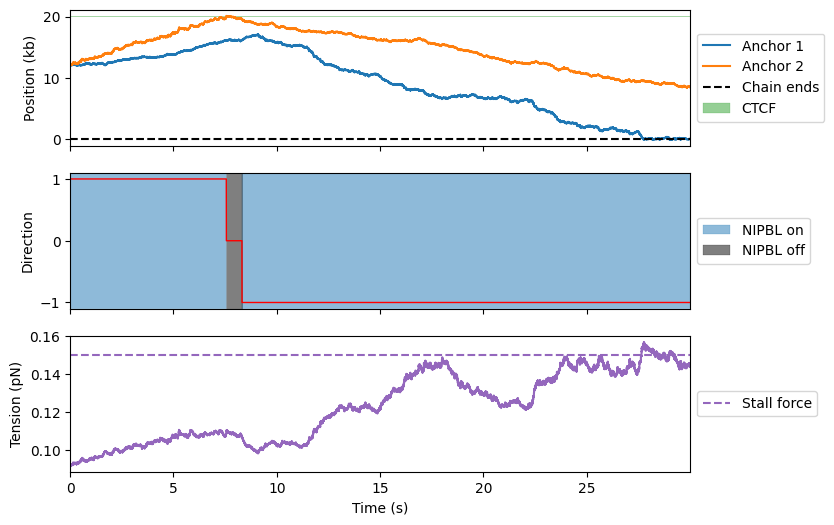

In [20]:
cohesin_id = 8

fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, sharex=True, figsize=(8,6))

plot_positions(cohesin_id, ax1, times, trajectory_kb)
plot_directions(cohesin_id, ax2, times, directions, states)
plot_tensions(cohesin_id, ax3, times, tensions)

plt.show()